# LangGraph Agentic Workflow

Agents-half add-on for **Session 03 (Lecture 2: Planning & Reflection)**. A multi-step LangGraph `StateGraph` workflow (nodes, edges, conditional routing, shared state) — the framework version of the hand-built ReAct/planning loop we build by hand in this session.


## ▶️ How to run this notebook (Colab **or** local VS Code / Jupyter)

This notebook works in both places — the setup cell below **auto-detects your environment** and does the right thing:

| | **Google Colab** | **Local (VS Code / Jupyter)** |
|---|---|---|
| Packages | installs everything for you | installs Python packages via `pip` |
| Graph pictures | uses system **Graphviz** (`draw_png`) | uses **Mermaid** (`draw_mermaid_png`, needs internet); falls back to a text diagram offline |
| System install | runs `apt-get install graphviz` | **skipped** (not available on macOS/Windows) |

**Just run the cells top-to-bottom.** You don't need to change anything by hand.

> 💡 Two cells use `input()` (the pizza demo). When you run them, type your answer in the box that appears and press Enter.


In [ ]:
# --- Environment-aware setup: works on both Colab and local (VS Code / Jupyter) ---

# Detect whether we're running inside Google Colab.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in", "Google Colab" if IN_COLAB else "a local environment (VS Code / Jupyter)")

# Core Python packages — needed everywhere.
%pip install -q -U langgraph langchain langchain-openai transformers

if IN_COLAB:
    # Colab can install system Graphviz, which lets pygraphviz render graphs via draw_png().
    !apt-get -qq install -y graphviz libgraphviz-dev
    %pip install -q pygraphviz
else:
    # Locally we skip apt-get (not available on macOS/Windows). Graphs render via Mermaid
    # instead (no system packages needed) — see the show_graph() helper below.
    print("Skipping system Graphviz install — graphs will render via Mermaid instead.")


Running in a local environment (VS Code / Jupyter)

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Skipping system Graphviz install — graphs will render via Mermaid instead.


Let us import necessary libraries

In [ ]:
from langgraph.graph import StateGraph, END
from typing import TypedDict


In [ ]:
# Helper: draw a compiled LangGraph graph using whatever works in this environment.
# We call show_graph(graph) everywhere instead of draw_png() directly, so the same
# notebook renders on Colab (Graphviz) and locally (Mermaid), with a text fallback offline.
from IPython.display import Image, display


def show_graph(graph):
    g = graph.get_graph()
    # 1) Graphviz / pygraphviz — best quality, available on Colab after apt-get.
    try:
        display(Image(g.draw_png()))
        return
    except Exception:
        pass
    # 2) Mermaid PNG — works locally with no system packages (needs internet).
    try:
        display(Image(g.draw_mermaid_png()))
        return
    except Exception:
        pass
    # 3) Offline fallback — a plain-text diagram that always works.
    print(g.draw_ascii())


LangGraph is a flowchart for AI agents — you connect nodes (agents/tools), and the graph manages state & flow.
For example, let us create an agentic workflow for Pizza order delivery

We will Define "State" which is the Class for our Agentic Flow. Nodes are the "hubs" or "centers" that carry on single task. Edges are connections between these "hubs"

In [ ]:

class PizzaState(TypedDict):
    order: str
    confirmed: bool

Create Nodes

Node 1: Take order.

Node 2: Confirm order.

Node 3: Finalize order.

In [ ]:
def take_order(state: PizzaState):
    print("Bot: Hi! What pizza do you want?")
    choice = input("You: ")
    state["order"] = choice
    return state

def confirm_order(state: PizzaState):
    print(f"Bot: You want a {state['order']} pizza, right?")
    confirmation = input("Confirm (yes/no): ")
    state["confirmed"] = confirmation.lower() == "yes"
    return state

def finalize_order(state: PizzaState):
    if state["confirmed"]:
        print(f"Bot: Great! Your {state['order']} pizza is on the way!")
    else:
        print("Bot:Oops order was not confirmed")
    return state

Build Graph

In [ ]:

workflow = StateGraph(PizzaState)

workflow.add_node("take_order", take_order)
workflow.add_node("confirm_order", confirm_order)
workflow.add_node("finalize_order", finalize_order)

workflow.set_entry_point("take_order")

workflow.add_edge("take_order", "confirm_order")
workflow.add_edge("confirm_order", "finalize_order")

graph = workflow.compile()

Visualize the graph

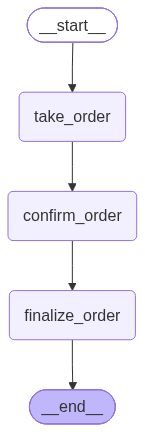

In [ ]:
# Visualize the Pizza workflow (renders on both Colab and local)
show_graph(graph)


Run the flow- try to test various output flows
1) Correct pizza name, respond yes for order confirmation
2) Wrong pizza name, respond no for order confirmation

In [8]:
graph.invoke({"order": "", "confirmed": False})

Bot: Hi! What pizza do you want?
Bot: You want a veggie pizza, right?
Bot: Great! Your veggie pizza is on the way!


{'order': 'veggie', 'confirmed': True}

Let us understand conditional edges.
Conditional edges are used to execure a node/hub based on a condition or an output of prior node/hub being a certain value. For example, The output of your last node confirming the order can be True or False. You can take different steps after this output based on the values True/False. If the order is not confirmed (False), you can restart the order process and if the order is confirmed (True) you can end the process.

In [9]:
def take_order(state: PizzaState):
    print("Bot: Hi! What pizza do you want?")
    choice = input("You: ")
    state["order"] = choice
    return state

def confirm_order(state: PizzaState):
    print(f"Bot: You want a {state['order']} pizza, right?")
    confirmation = input("Confirm (yes/no): ")
    state["confirmed"] = confirmation.lower() == "yes"
    return state

def finalize_order(state: PizzaState):
    print(f"Bot: Great! Your {state['order']} pizza is on the way!")
    return state

In [10]:
from langgraph.graph import StateGraph, END

workflow = StateGraph(PizzaState)

workflow.add_node("take_order", take_order)
workflow.add_node("confirm_order", confirm_order)
workflow.add_node("finalize_order", finalize_order)

workflow.set_entry_point("take_order")

# Normal edge from taking order → confirmation
workflow.add_edge("take_order", "confirm_order")

# Conditional edges from confirmation
def decide_next(state: PizzaState):
    if state["confirmed"]:
        return "finalize_order"
    else:
        return "take_order"   # loop back if not confirmed

workflow.add_conditional_edges(
    "confirm_order",
    decide_next,   # function that decides next node
    {"finalize_order": "finalize_order", "take_order": "take_order"}
)

graph = workflow.compile()

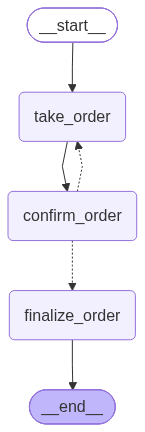

In [11]:
# Visualize the conditional-edge workflow (renders on both Colab and local)
show_graph(graph)


In [12]:
# Run the graph
graph.invoke({"order": "", "confirmed": False})


Bot: Hi! What pizza do you want?
Bot: You want a beggie pizza, right?
Bot: Hi! What pizza do you want?
Bot: You want a cheese pizza, right?
Bot: Great! Your cheese pizza is on the way!


{'order': 'cheese', 'confirmed': True}

Let us try a bit more complex example with a smart orchestrator that understands your query and routes it to appropriate department. Imagine you are in an amusement park and you go to the information desk. Based on the topic of your query, appropriate node/department is chosen to answer it.

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, END
from transformers import pipeline
import random

# Fallback text-generation model, with an automatic downgrade for smaller laptops.
# - Preferred: Qwen2.5-0.5B-Instruct (~1 GB) — instruction-tuned, so replies stay on-topic.
# - If it can't load (limited RAM/disk, no download, etc.), we automatically fall back to
#   the tiny distilgpt2 (~350 MB). To force the small model, set PREFERRED_MODEL = FALLBACK_MODEL.
PREFERRED_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
FALLBACK_MODEL = "distilgpt2"

try:
    generator = pipeline("text-generation", model=PREFERRED_MODEL)
    USING_CHAT_MODEL = True
    print(f"Loaded {PREFERRED_MODEL} (instruction-tuned).")
except Exception as err:
    print(f"Could not load {PREFERRED_MODEL} ({type(err).__name__}); falling back to {FALLBACK_MODEL} for smaller machines.")
    generator = pipeline("text-generation", model=FALLBACK_MODEL)
    USING_CHAT_MODEL = False

class ParkState(TypedDict):
    query: str
    answer: str
    selected_node: str


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
# Orchestrator decides which node to go to
# Orchestrator updates state with the routing decision
def orchestrator(state: ParkState):
    q = state["query"].lower()
    if "ride" in q:
        state["selected_node"] = "rides_info"
    elif "food" in q or "eat" in q:
        state["selected_node"] = "food_info"
    elif "ticket" in q or "price" in q:
        state["selected_node"] = "tickets_info"
    else:
        state["selected_node"] = "fallback"
    return state

def rides_info(state: ParkState):
    rides = ["Roller Coaster", "Haunted Mansion", "Ferris Wheel"]
    state["answer"] = f"Our park has amazing rides like {random.choice(rides)}!"
    return state

def food_info(state: ParkState):
    foods = ["pizza", "hot dogs", "ice cream", "milkshakes"]
    state["answer"] = f"You’ll love our food court! We serve {random.choice(foods)}."
    return state

def tickets_info(state: ParkState):
    state["answer"] = "Tickets are $20 for kids and $35 for adults."
    return state

def fallback(state: ParkState):
    # Use whichever small LLM loaded above to answer playfully.
    if USING_CHAT_MODEL:
        # Instruction-tuned model: chat-format messages apply Qwen's chat template automatically.
        messages = [
            {"role": "system", "content": "You are a fun, friendly amusement-park info desk assistant. Reply in one short, playful sentence."},
            {"role": "user", "content": state["query"]},
        ]
        gen = generator(messages, max_new_tokens=40, do_sample=True, temperature=0.7)
        state["answer"] = gen[0]["generated_text"][-1]["content"].strip()
    else:
        # Plain GPT-2 style model: prompt in, continuation out (strip the prompt back off).
        prompt = f"The user asked: {state['query']}. Respond playfully:"
        gen = generator(prompt, max_new_tokens=40, do_sample=True, temperature=0.7, truncation=True)
        text = gen[0]["generated_text"]
        state["answer"] = text[len(prompt):].strip() or text.strip()
    return state


NameError: name 'ParkState' is not defined

In [ ]:
workflow = StateGraph(ParkState)

# Add nodes
workflow.add_node("orchestrator", orchestrator)
workflow.add_node("rides_info", rides_info)
workflow.add_node("food_info", food_info)
workflow.add_node("tickets_info", tickets_info)
workflow.add_node("fallback", fallback)

# Entry point is orchestrator
workflow.set_entry_point("orchestrator")

# Conditional routing
workflow.add_conditional_edges(
    "orchestrator",
    lambda state: state["selected_node"],
    {
        "rides_info": "rides_info",
        "food_info": "food_info",
        "tickets_info": "tickets_info",
        "fallback": "fallback",
    }
)

# All info nodes end workflow
workflow.add_edge("rides_info", END)
workflow.add_edge("food_info", END)
workflow.add_edge("tickets_info", END)
workflow.add_edge("fallback", END)

graph = workflow.compile()


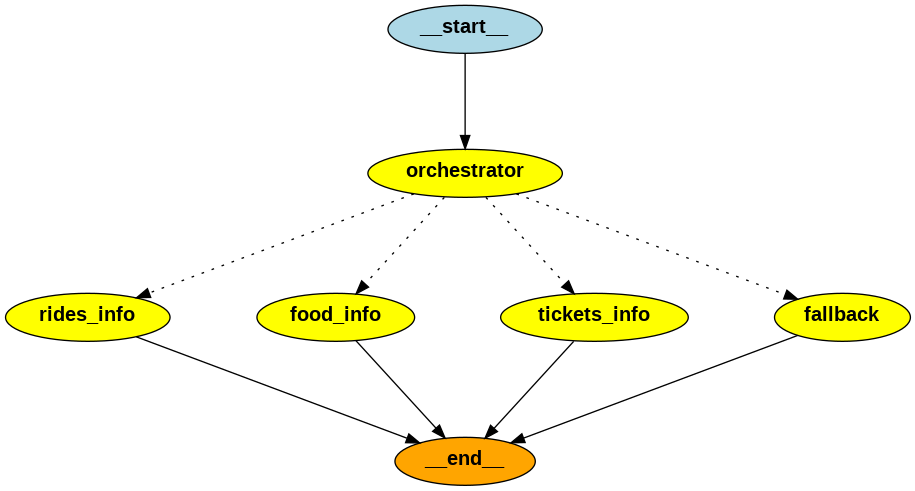

In [ ]:
# Visualize the orchestrator/router workflow (renders on both Colab and local)
show_graph(graph)


In [ ]:
# Try different queries!
queries = [
    "What rides do you have?",
    "Where can I eat?",
    "How much are the tickets?",
]

for q in queries:
    print("\n User:", q)
    result = graph.invoke({"query": q, "answer": ""})
    print("Bot:", result["answer"])
